# Домашнее задание 3. Градиентный спуск, Ньютон, BFGS: реализация и сравнение

**Выдано:** 7 октября 2026. **Срок сдачи:** 21 октября 2026 (до начала занятия). **Максимум:** 10 баллов (+1 бонус).

**Как сдавать.** Заполните этот ноутбук (ответы на теоретические вопросы — в markdown-ячейках, формулы в $\LaTeX$; код — в code-ячейках), выполните целиком (`Kernel → Restart Kernel and Run All Cells`) и сдайте через pull request: файл `submissions/hw03/<фамилия>.ipynb`, инструкция — [`CONTRIBUTING.md`](../CONTRIBUTING.md). Задачи можно обсуждать, но текст и код пишутся самостоятельно.

**Материал:** лекция 4 ([конспект](../lectures/lecture04/lecture04.md)) и лекция 5 ([конспект](../lectures/lecture05/lecture05.md), [демо](../lectures/lecture05/demo05.ipynb), [семинар](../lectures/lecture05/seminar05.ipynb)). Ничего сверх лекций не требуется. Ориентировочное время — 3–4 часа.

**Устройство задания.** Обвязка — функции Розенброка, цепь, данные синуса, рисовальщики — дана готовой в ячейке ниже; вы пишете только то, что составляет метод: направление, выбор длины шага, обновление матрицы, шаг Гаусса–Ньютона. Под каждым заданием стоит проверка (`assert`), которая ловит смысл: если она прошла, можно идти дальше. Все методы работают с одними и теми же параметрами, чтобы числа совпали с конспектом: backtracking по Армихо с $c=10^{-4}$ от $\alpha=1$ делением пополам, останов по $\lVert\nabla f\rVert\le10^{-6}$ (у Ньютона — $10^{-10}$).

Запуск: `uv sync` в корне репозитория, затем `uv run jupyter lab`; в Colab ничего ставить не нужно.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, least_squares

rng = np.random.default_rng(2026)   # не меняйте seed: данные должны совпадать у всех

BLUE, ORANGE, AQUA, RED, VIOLET, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#4a3aa7", "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- задачи (даны готовыми)
def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0] ** 2), 200 * (x[1] - x[0] ** 2)])


def rosen_hess(x):
    return np.array([[2 - 400 * x[1] + 1200 * x[0] ** 2, -400 * x[0]], [-400 * x[0], 200.0]])


X0_ROSEN = np.array([-1.2, 1.0])


def make_chain(N, D=70.0, g=9.81):
    """Цепь без пола (лекция 1, §7.3; лекция 4): E(v) = 1/2 v^T H v + b^T v + const.
    Возвращает (energy, grad_E, H, b, v0): функция, градиент, гессиан, линейный член, старт (прямая между концами)."""
    m = 4.0 / N
    K = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    H = np.kron(np.eye(2), D * K)
    b = np.zeros(2 * N)
    b[0] -= D * (-2.0); b[N - 1] -= D * 2.0; b[N] -= D * 1.0; b[2 * N - 1] -= D * 1.0; b[N:] += m * g
    v0 = np.r_[np.linspace(-2, 2, N + 2)[1:-1], np.ones(N)]

    def energy(v):
        y, z = np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]
        return 0.5 * D * np.sum(np.diff(y) ** 2 + np.diff(z) ** 2) + m * g * np.sum(z[1:-1])

    return energy, (lambda v: H @ v + b), H, b, v0


# данные задачи 2(б) ДЗ 2: y = 2 sin(3t + 0.7) + шум, 60 точек, те же 20 стартов
data_rng = np.random.default_rng(2026)
t_data = np.sort(data_rng.uniform(0, 2 * np.pi, 60))
y_data = 2.0 * np.sin(3.0 * t_data + 0.7) + 0.2 * data_rng.standard_normal(60)
starts = data_rng.uniform(-5, 5, (20, 3))
X0_SINE = np.array([1.0, 3.0, 0.0])


def sine_resid(x):
    """Невязки модели x1 sin(x2 t + x3) на данных."""
    return x[0] * np.sin(x[1] * t_data + x[2]) - y_data


def sine_jac(x):
    """Якобиан невязок (60 x 3): столбцы — производные по амплитуде, частоте, фазе."""
    s, c = np.sin(x[1] * t_data + x[2]), np.cos(x[1] * t_data + x[2])
    return np.c_[s, x[0] * t_data * c, x[0] * c]


def sine_f(x):
    r = sine_resid(x); return 0.5 * (r @ r)


def sine_grad(x):
    return sine_jac(x).T @ sine_resid(x)


# ---------------------------------------------------------------- рисовальщики (принимают ax=None, возвращают ax)
def plot_rosen_path(paths, labels=None, ax=None, xlim=(-2.2, 2.2), ylim=(-3.5, 3.2), every=50):
    """Линии уровня Розенброка и пути методов; длинные пути прореживаются (каждая every-я точка после 30-й)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    X, Y = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    ax.contour(X, Y, (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2, levels=np.logspace(-1, 3.3, 14), colors=[GRAY], linewidths=0.7)
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, p in enumerate(paths):
        pp = p if len(p) <= 60 else np.r_[p[:30], p[30::every]]
        ax.plot(pp[:, 0], pp[:, 1], "-o", ms=3 if len(p) > 60 else 4.5, lw=1.3, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.plot(1, 1, "*", ms=13, color=RED, mec="white", zorder=7)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$x_1$", ylabel="$x_2$"); ax.grid(False)
    if labels is not None:
        ax.legend(loc="upper left", fontsize=8)
    return ax


def plot_grad_norms(gnorms, labels=None, ax=None):
    """log10 нормы градиента по итерациям для нескольких методов (ось итераций логарифмическая)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 4.2))
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, gn in enumerate(gnorms):
        ax.plot(np.arange(1, len(gn) + 1), np.log10(np.asarray(gn) + 1e-17), "-o" if len(gn) < 60 else "-", ms=3.5, lw=1.4, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.set_xscale("log"); ax.set(xlabel="итерация $k$ (лог. шкала)", ylabel="$\\log_{10}\\Vert\\nabla f(x_k)\\Vert$")
    if labels is not None:
        ax.legend(fontsize=8)
    return ax


print("данные синуса:", t_data.shape, " стартов ДЗ 2:", len(starts), " f в старте (1, 3, 0):", round(sine_f(X0_SINE), 3))

данные синуса: (60,)  стартов ДЗ 2: 20  f в старте (1, 3, 0): 33.867


## Задача 1. Теория (4 балла)

По 1 баллу за пункт. Нужны выкладки, а не только ответ; численная проверка приветствуется, но текстом объясните, почему так.

**(а) Один шаг Ньютона.** $f(x)=x_1^2+2x_2^2+x_1x_2-4x_1-7x_2$. Из точки $x_0=(0,0)$ сделайте один шаг Ньютона руками: выпишите $\nabla f(x_0)$, $\nabla^2f$, решите систему $Hp=-g$ и проверьте, что в новой точке $\nabla f=0$. Почему здесь хватило одной итерации и какое свойство функции за это отвечает?

**(б) Цифры удваиваются.** Метод Ньютона для $F(x)=x^2-a$ даёт $x_{k+1}=\tfrac12(x_k+a/x_k)$. Покажите, что ошибка $e_k=x_k-\sqrt a$ удовлетворяет $e_{k+1}=\dfrac{e_k^2}{2x_k}$. Для $a=3$, $x_0=2$ выпишите $x_1,x_2,x_3$ и ошибки; сколько верных цифр прибавляет каждый шаг?

**(в) Секущее уравнение для $B$.** Обновление BFGS для самого гессиана (не обратного): $B_{k+1}=B_k-\dfrac{B_ks_ks_k^\top B_k}{s_k^\top B_ks_k}+\dfrac{y_ky_k^\top}{y_k^\top s_k}$. Проверьте подстановкой, что $B_{k+1}s_k=y_k$. Почему для этого нужно $y_k^\top s_k\ne0$, и что это условие означает для функции?

**(г) Что отбрасывает Гаусс–Ньютон.** $f(x)=\tfrac12\lVert r(x)\rVert^2$, $r(x)=\big(x_1-2,\ x_2-1,\ x_1x_2-1\big)$. Выпишите $J$, $J^\top J$ и полный гессиан $\nabla^2f=J^\top J+\sum_ir_i\nabla^2r_i$. Где отброшенный член равен нулю? Есть ли у этой задачи точка, где все невязки нулевые, и что это значит для сходимости Гаусса–Ньютона рядом с ней?

**(а)**

**Ответ:** 

1) Градиент в точке (0; 0): $\nabla f(x) = \begin{pmatrix} 2x_1+x_2-4 \\ 4x_2+x_1-7 \end{pmatrix}; \nabla f(0;0)=\begin{pmatrix} -4 \\ -7 \end{pmatrix} = g$  

2) Гессиан: $H = \nabla^{2}f = \begin{pmatrix} 2 & 1 \\ 1 & 4 \end{pmatrix}$

3) $Hp=-g; \begin{pmatrix} 2 & 1 \\ 1 & 4 \end{pmatrix} \begin{pmatrix} p_1 \\ p_2 \end{pmatrix} = \begin{pmatrix} -4 \\ -7 \end{pmatrix} \Longrightarrow p_1=\frac{9}{7}, p_2=\frac{10}{7}, x_1 = (\frac{9}{7}; \frac{10}{7})$

4) Проверка $\nabla f(x_1) = 0$: $\nabla f(x_1) = \begin{pmatrix} 2*\frac{9}{7}+\frac{10}{7}-4 \\ 4*\frac{10}{7}+\frac{9}{7}-7 \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}$=2орядка остаток тождественно равен нулю.  
Можно функцию f представить в виде: $f(x) = \frac{1}{2}x^\top H x + c^\top x$, где $c=\nabla f(0)$. Тогда градиент имеет вид: $\nabla f(x)=Hx+c$.  
Метод Ньютона делает шаг из $x_0=0$: $x_1=x_0-H^{-1}c = -H^{-1}c$. В этой точке градиент нулевой. Аналитическое решение уравнения $\nabla f(x) = Hx + \nabla f(x_0) = 0$

**(б)**

**Ответ:** 

1) Покажем, что ошибка $e_k$ удовлетворяет уравнению $e_{k+1} = \frac{e_k^2}{2x_k}$: $e_{k+1}=x_{k+1} - \sqrt{a} = \frac{1}{2} (x_k + \frac{a}{x_k}) - \sqrt{a} = \frac{x_k^2 + a - 2\sqrt{a}x_k^2}{2x_k} = \frac{(x_k - \sqrt{a})^2}{2x_k} = \frac{e_k^2}{2x_k}$ (ч.т.д)  

2) Для $a=3,x_0=2$: 
    - $x_1=\frac{1}{2}(2 + \frac{3}{2}) = \frac{7}{4}; e_1=\frac{7}{4} - \sqrt{3} \approx 1,795 * 10^-2$. Верных цифр: 1
    - $x_2=\frac{1}{2}(\frac{7}{4} + \frac{3*4}{7}) = \frac{97}{56}; e_1=\frac{97}{56} - \sqrt{3} \approx 9,205 * 10^-5$. Верных цифр: 4
    - $x_3=\frac{1}{2}(\frac{97}{56} + \frac{3*56}{97}) = \frac{18817}{10864}; e_1=\frac{18817}{10864} - \sqrt{3} \approx 2,4 * 10^-9$. Верных цифр: 8

**(в)**

**Ответ:** 

1) Проверем, что $B_{k+1}s_k=y_k$ при $B_{k+1} = B_k - \frac{B_k s_k s_k^\top B_k}{s_k ^ \top B_k s_k} + \frac{y_k y_k^\top}{y_k^\top s_k}$:  
$B_{k+1}s_k=B_k s_k - \frac{B_k s_k (s_k^\top B_k s_k)}{s_k^\top B_k s_k} + \frac{y_k(y_k^\top s_k)}{y_k^\top s_k}$.  
Сократив дроби и выполнив разницу между первым и вторым членом - получаем: $B_{k+1}s_k = y_k$ при условии, что $y_k^\top s_k \neq 0$ и $s_k^\top B_k s_k \neq 0$.  
$y_k = \nabla f(x_{k+1}) - \nabla f(x_k); s_k=x_{k+1}-x_k$  
Условие $y_k^\top s_k = (\nabla f(x_{k+1}) - \nabla f(x_k))^\top (x_{k+1}-x_k)$ является условием строгой монотонности градиента, которое выполняется для строго выпуклых функций.

**(г)**

**Ответ:** 

1) $J=\begin{pmatrix} 1 & 0 \\ 0 & 1 \\ x_2 & x_1 \end{pmatrix}$
2) $J^\top J = \begin{pmatrix} 1 & 0 & x_2\\ 0 & 1 & x_1 \end{pmatrix} \begin{pmatrix} 1 & 0 \\ 0 & 1 \\ x_2 & x_1 \end{pmatrix} = \begin{pmatrix} 1+x_2^2 & x_1x_2 \\ x_1x_2 & 1+x_1^2 \end{pmatrix}$
3) $\nabla^2f=J^\top J+\sum_ir_i\nabla^2r_i = \begin{pmatrix} 1+x_2^2 & x_1x_2 \\ x_1x_2 & 1+x_1^2 \end{pmatrix} + (x_1x_2-1)\begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} = \begin{pmatrix} 1+x_2^2 & 2x_1x_2 - 1 \\ 2x_1x_2 - 1 & 1+x_1^2 \end{pmatrix}$
    - $\nabla^2 r_1 = \nabla^2(x_1 - 2) = 0$
    - $\nabla^2 r_2 = \nabla^2(x_2 - 2) = 0$
    - $\nabla^2 r_3 = \nabla^2(x_1x_2 - 2) = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix}$

4) Отброшенный член равен нулю при $r_3 = x_1x_2 - 1 = 0$, то есть на гиперболе $x_1x_2=1$

5) Для $r=0$ надо, чтобы $r_1=0,r_2=0,r_3=0$, то есть $x_1=2, x_2=1, x_1x_2=1$. Отсюда следует, что таких решений нет. Из-за этого отброшенный член не зануляется вблизи решения, и модель гессиана имеет смещение. Гаусс-Ньютон будет сходиться линейно, а не квадратично.

## Задача 2. Практика (6 баллов)

### (а) Три кирпича методов (2 балла)

Метод Ньютона с backtracking и BFGS собираются из трёх частей; каждую пишете отдельно, под каждой — проверка. Сигнатуры не меняйте: ниже готовые циклы `newton_damped` и `bfgs` используют именно их.

**TODO 1 — направление Ньютона.** `newton_direction(g, H)` возвращает $p$ — решение $Hp=-g$. Если $g^\top p\ge0$ (направление не спуск — гессиан индефинитен), верните вместо него решение системы с регуляризованной матрицей $H+(\lvert\lambda_{\min}\rvert+10^{-3})I$.

In [2]:
def newton_direction(g, H):
    """Направление Ньютона p = -H^{-1} g; при g^T p >= 0 — регуляризация H + (|lambda_min| + 1e-3) I."""

    p = np.linalg.solve(H, -g)
    
    if g @ p >= 0:
        lambda_min = np.min(np.linalg.eigvalsh(H))
        tau = np.abs(lambda_min) + 1e-3
        H_reg = H + tau * np.eye(H.shape[0])
        p = np.linalg.solve(H_reg, -g)
        
    return p

In [3]:
# проверка TODO 1: на квадратичной из задачи 1(а) один шаг попадает в минимум; при индефинитном H направление — спуск
H_q = np.array([[2.0, 1.0], [1.0, 4.0]]); g_q = np.array([-4.0, -7.0])
assert np.allclose(newton_direction(g_q, H_q), [9 / 7, 10 / 7]), "на квадратичной 1(а) шаг Ньютона должен быть (9/7, 10/7): проверьте знак в решении системы"
H_ind = np.diag([1.0, -1.0]); g_ind = np.array([0.0, 1.0])
assert g_ind @ newton_direction(g_ind, H_ind) < 0, "при индефинитном H и g = (0, 1) чистый шаг (0, 1) идёт вверх — нужна регуляризация"
print("TODO 1: ok")

TODO 1: ok


**TODO 2 — длина шага по Армихо.** `armijo(f, x, p, g, c=1e-4)` возвращает $\alpha$: начинаем с $\alpha=1$ и делим пополам, пока не выполнено $f(x+\alpha p)\le f(x)+c\,\alpha\,g^\top p$ (лекция 4, §4.5; лекция 5, §3.4).

In [4]:
def armijo(f, x, p, g, c=1e-4):
    """Backtracking: alpha = 1, делим пополам до выполнения условия Армихо."""
    alpha = 1.0
    fx = f(x)
    gp = g @ p
    
    while f(x + alpha * p) > fx + c * alpha * gp:
        alpha /= 2.0
    
    return alpha

In [5]:
# проверка TODO 2: на f = 1/2 (x1^2 + 10 x2^2) из (3, 1) вдоль -g первый принятый шаг — ровно 1/8 (лекция 4, картинка 03)
Q2 = np.diag([1.0, 10.0]); f2 = lambda x: 0.5 * x @ Q2 @ x
x2 = np.array([3.0, 1.0]); g2 = Q2 @ x2
a = armijo(f2, x2, -g2, g2)
assert abs(a - 0.125) < 1e-12, f"ожидался шаг 1/8, получен {a}: делите пополам, начиная с 1, и проверяйте условие с c * alpha * g^T p"
assert armijo(f2, x2, -g2 * 1e-3, g2) == 1.0, "короткое направление должно приниматься целиком (alpha = 1)"
print("TODO 2: ok")

TODO 2: ok


**TODO 3 — обновление BFGS.** `bfgs_update(H, s, y)` возвращает $H_{k+1}=(I-\rho sy^\top)H(I-\rho ys^\top)+\rho ss^\top$, $\rho=1/(y^\top s)$ (лекция 5, §4.3).

In [6]:
def bfgs_update(H, s, y):
    """Обновление обратного гессиана BFGS по паре (s, y)."""
    rho = 1.0 / (y @ s)
    n = len(s)
    I = np.eye(n)
    
    A = I - rho * np.outer(s, y)
    B = I - rho * np.outer(y, s)
    
    H_new = A @ H @ B + rho * np.outer(s, s)
    
    return H_new

In [7]:
# проверка TODO 3: секущее уравнение, симметрия, H > 0; на квадратичной kappa = 50 из (50, 1) с точным шагом два обновления дают H_2 = Q^{-1} (упражнение 11.5)
Hs = np.eye(3); s_, y_ = np.array([1.0, -2.0, 0.5]), np.array([0.5, -1.0, 2.0])
Hn = bfgs_update(Hs, s_, y_)
assert np.allclose(Hn @ y_, s_), "секущее уравнение H_{k+1} y = s нарушено: проверьте порядок s и y в формуле"
assert np.allclose(Hn, Hn.T) and np.all(np.linalg.eigvalsh(Hn) > 0), "H_{k+1} должна быть симметричной и положительно определённой при s^T y > 0"
Q50 = np.diag([1.0, 50.0]); xq = np.array([50.0, 1.0]); Hq = np.eye(2)
for _ in range(2):
    gq = Q50 @ xq; pq = -Hq @ gq; aq = -(gq @ pq) / (pq @ Q50 @ pq)      # точный шаг на квадратичной
    sq = aq * pq; xq = xq + sq; Hq = bfgs_update(Hq, sq, Q50 @ sq)
assert np.allclose(Hq, np.linalg.inv(Q50), atol=1e-10) and np.allclose(xq, 0, atol=1e-9), "после двух обновлений на квадратичной 2x2 должно получиться H_2 = Q^{-1} = diag(1, 0.02) и x_2 = 0"
print("TODO 3: ok;  H_2 =", Hq.round(6).tolist())

TODO 3: ok;  H_2 = [[1.0, 0.0], [0.0, 0.02]]


Сборка методов из кирпичей — дана готовой (сравните с лекцией: это ровно `newton_damped` и `bfgs` из `l5helpers.py`). `gd` — градиентный спуск с backtracking из лекции 4, тоже через ваш `armijo`.

In [8]:
def gd(f, grad, x0, alpha=None, tol=1e-6, maxit=100_000):
    """Градиентный спуск: alpha=None — backtracking по Армихо, иначе постоянный шаг. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        a = armijo(f, x, -g, g) if alpha is None else alpha
        x = x - a * g; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def newton_damped(f, grad, hess, x0, tol=1e-10, maxit=200):
    """Ньютон с backtracking. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = newton_direction(g, hess(x))
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def bfgs(f, grad, x0, tol=1e-6, maxit=10_000):
    """BFGS с H_0 = I и backtracking по Армихо. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); H = np.eye(len(x)); g = grad(x); path = [x.copy()]; gnorm = [np.linalg.norm(g)]
    for k in range(maxit):
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = -H @ g
        s = armijo(f, x, p, g) * p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if s @ y > 1e-12:                                   # условие кривизны, иначе H не трогаем
            H = bfgs_update(H, s, y)
        x, g = x_new, g_new; path.append(x.copy()); gnorm.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(gnorm)


print("методы собраны")

методы собраны


### (б) Розенброк и цепь: сравнение (2 балла)

1. Запустите три метода на Розенброке из $(-1.2,\,1)$ (спуск и BFGS — до $\lVert\nabla f\rVert\le10^{-6}$, Ньютон — до $10^{-10}$). Напечатайте таблицу: метод, число итераций, число вычислений $f$ (добавьте счётчик — например, обёрткой вокруг `rosen`), конечная точка. Ожидаемые числа конспекта — $13\,756$, $22$, $34$; расхождение до $5\,\%$ допустимо.
2. Нарисуйте две картинки готовыми рисовальщиками: пути трёх методов на линиях уровня (`plot_rosen_path`) и $\log_{10}\lVert\nabla f(x_k)\rVert$ по итерациям (`plot_grad_norms`). Назовите по графику тип сходимости каждого метода (лекция 4, §6; лекция 5, §3–4).
3. Цепь $N=40$: спуск с постоянным шагом $1/L$ ($L=\lambda_{\max}(H)$) против одного шага Ньютона `v0 - solve(H, grad(v0))`: число итераций, энергия в конце, расхождение решений. Затем запустите **ваш** `bfgs` на цепи $N=10$ и $N=20$ с `maxit=10_000`: сошёлся ли он? Объясните результат одним абзацем через §4.5 конспекта (что ломается у BFGS с одним лишь backtracking и что это лечит).

Критерии: полный балл — таблица с числами в пределах допуска, обе картинки, верно названные типы сходимости и внятное объяснение по цепи; половина — методы работают, но без анализа.

Метод        | Итерации | Выч. f(x)  | Конечная точка           
-----------------------------------------------------------------
GD           | 13756    | 150555     | [1. 1.]
Newton       | 22       | 51         | [1. 1.]
BFGS         | 34       | 87         | [1. 1.]


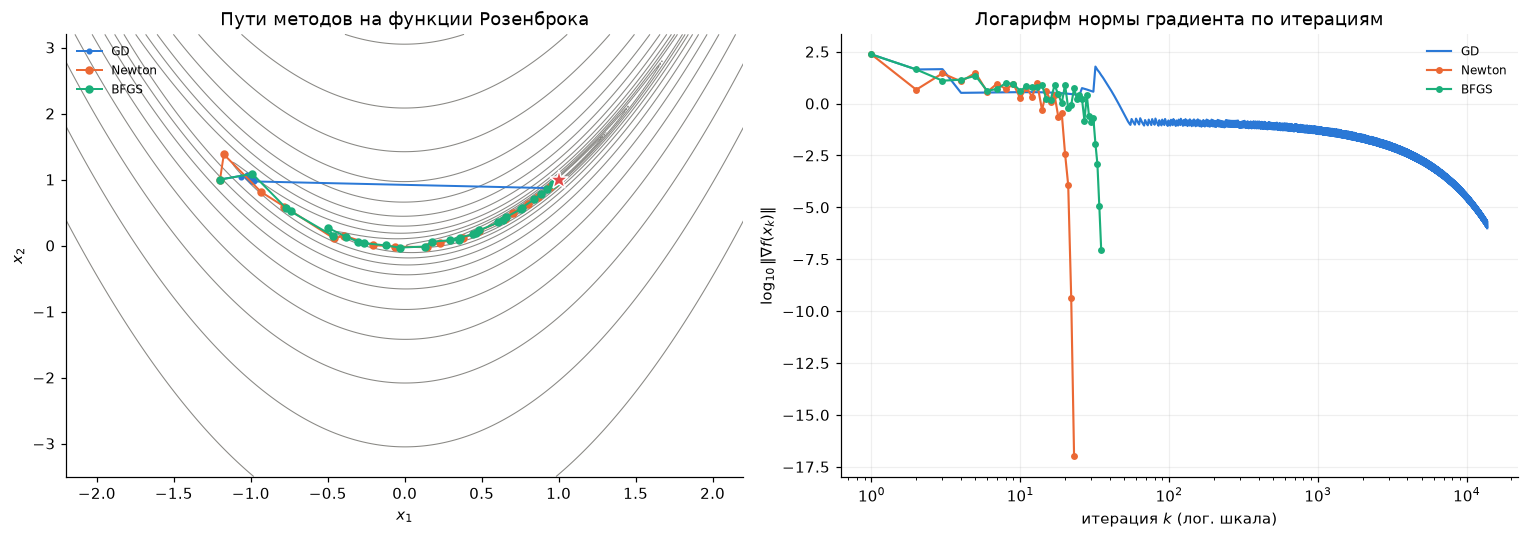

N=40: GD (шаг 1/L) потребовал 10575 итераций. Энергия: 13.441736
N=40: Ньютон (1 шаг). Энергия: 13.441736
Расхождение решений (норма разности): 2.43e-06

Запуск BFGS на цепи:
N=10: Итераций: 40    | Сошёлся: Да  | Мин. норма градиента: 4.32e-09
N=20: Итераций: 10000 | Сошёлся: Нет (достигнут лимит) | Мин. норма градиента: 1.69e-06


In [11]:
# --- 1 ---
class FuncCounter:
    def __init__(self, f):
        self.f = f
        self.count = 0
    def __call__(self, x):
        self.count += 1
        return self.f(x)

rosen_counted = FuncCounter(rosen)

rosen_counted.count = 0
x_gd, it_gd, path_gd, gnorm_gd = gd(rosen_counted, rosen_grad, X0_ROSEN, tol=1e-6)
evals_gd = rosen_counted.count

rosen_counted.count = 0
x_newton, it_newton, path_newton, gnorm_newton = newton_damped(rosen_counted, rosen_grad, rosen_hess, X0_ROSEN, tol=1e-10)
evals_newton = rosen_counted.count

rosen_counted.count = 0
x_bfgs, it_bfgs, path_bfgs, gnorm_bfgs = bfgs(rosen_counted, rosen_grad, X0_ROSEN, tol=1e-6)
evals_bfgs = rosen_counted.count

print(f"{'Метод':<12} | {'Итерации':<8} | {'Выч. f(x)':<10} | {'Конечная точка':<25}")
print("-" * 65)
print(f"{'GD':<12} | {it_gd:<8} | {evals_gd:<10} | {np.round(x_gd, 4)}")
print(f"{'Newton':<12} | {it_newton:<8} | {evals_newton:<10} | {np.round(x_newton, 4)}")
print(f"{'BFGS':<12} | {it_bfgs:<8} | {evals_bfgs:<10} | {np.round(x_bfgs, 4)}")

# --- 2 ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_rosen_path([path_gd, path_newton, path_bfgs], 
                labels=["GD", "Newton", "BFGS"], 
                ax=ax1)
ax1.set_title("Пути методов на функции Розенброка")

plot_grad_norms([gnorm_gd, gnorm_newton, gnorm_bfgs], 
                labels=["GD", "Newton", "BFGS"], 
                ax=ax2)
ax2.set_title("Логарифм нормы градиента по итерациям")

plt.tight_layout()
plt.show()

# --- 3 ---
E40, grad_E40, H40, b40, v0_40 = make_chain(40)
L40 = np.max(np.linalg.eigvalsh(H40))
alpha_40 = 1.0 / L40

x_gd_chain, it_gd_chain, _, gnorm_gd_chain = gd(E40, grad_E40, v0_40, alpha=alpha_40, tol=1e-6)
energy_gd = E40(x_gd_chain)

v_newton_40 = v0_40 - np.linalg.solve(H40, grad_E40(v0_40))
energy_newton = E40(v_newton_40)
diff_solutions = np.linalg.norm(x_gd_chain - v_newton_40)

print(f"N=40: GD (шаг 1/L) потребовал {it_gd_chain} итераций. Энергия: {energy_gd:.6f}")
print(f"N=40: Ньютон (1 шаг). Энергия: {energy_newton:.6f}")
print(f"Расхождение решений (норма разности): {diff_solutions:.2e}")

print("\nЗапуск BFGS на цепи:")
for N in [10, 20]:
    E_N, grad_E_N, H_N, b_N, v0_N = make_chain(N)
    x_bfgs_N, it_bfgs_N, _, gnorm_bfgs_N = bfgs(E_N, grad_E_N, v0_N, tol=1e-6, maxit=10_000)
    converged = "Да" if it_bfgs_N < 10_000 else "Нет (достигнут лимит)"
    print(f"N={N:<2}: Итераций: {it_bfgs_N:<5} | Сошёлся: {converged:<3} | Мин. норма градиента: {np.min(gnorm_bfgs_N):.2e}")

**Ответ:**  

2) 
    - Градиентный спуск: линейная сходимость
    - BFGS: сверхлинейная сходимость
    - Ньютон: квадратичная сходимость

3) Градиентный спуск с шагом $\frac{1}{L}$ сошёлся за 10575 итераций, метод Ньютона - за 1 шаг.  
BFGS для цепи $N=10$ сошёлся. Для $N=20$ - нет (из-за достигнутого лимита в 10000 операций).  
Используемое правило Армихо не гарантирует выполнение условия кривизны $y_k^\top s_k \gt 0$.  
Если на каком-то шаге $y_k^\top s_k \le 0$, то матрица $H_k$ не обновляется, чтобы не потерять положительную определённость. Метод деградирует до градиентного спуска.  
Проблема лечится добавлением условия кривизны Вольфе, которое требует, чтобы наклон вдоль направления шага стал менее отрицательным, позволяя BFGS корректно восстановить обратный гессиан.

### (в) Гаусс–Ньютон на синусе из ДЗ 2 (2 балла)

**TODO 4 — шаг Гаусса–Ньютона.** Допишите в `gauss_newton` строку с направлением: $p$ — решение линейного МНК $\min_p\lVert Jp+r\rVert^2$ (`np.linalg.lstsq`). Длина шага — ваш `armijo` на $f=\tfrac12\lVert r\rVert^2$ (демпфированный Гаусс–Ньютон). Проверка под ячейкой: на **линейных** невязках $r=Ax-b$ метод обязан сойтись за одну итерацию к `lstsq`.

Затем:

1. Запустите из $(1,\,3,\,0)$: ожидается $7$ итераций и $f^\ast=1.1393$, $x^\ast\approx(2.10,\,2.997,\,0.700)$. Сравните с вашим `bfgs` на `sine_f` из того же старта (итерации и вызовы функции) и со спуском ($731$ итерация в конспекте).
2. Запустите из всех 20 стартов `starts` ДЗ 2 (`maxit=200`). Сколько стартов пришли к глобальному $f^\ast=1.1393$ (с точностью $10^{-6}$)? Нарисуйте данные и все 20 подогнанных кривых одной картинкой. Объясните в двух предложениях, почему быстрый локальный метод не отменяет мультистарт из ДЗ 2.

Критерии: полный балл — проверка на линейных невязках проходит, числа пункта 1 воспроизведены, картинка и объяснение; половина — метод сходится, но без сравнения или без мультистарта.

In [12]:
def gauss_newton(resid, jac, x0, tol=1e-6, maxit=100):
    """Демпфированный Гаусс–Ньютон для f = 1/2 ||r||^2. Возвращает (x, итераций, путь, нормы градиента)."""
    f = lambda x: 0.5 * np.sum(resid(x) ** 2)
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    
    for k in range(maxit):
        r, J = resid(x), jac(x)
        g = J.T @ r
        gnorm.append(np.linalg.norm(g))
        
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
            
        p = np.linalg.lstsq(J, -r, rcond=None)[0]
        
        x = x + armijo(f, x, p, g) * p
        path.append(x.copy())
        
    return x, maxit, np.array(path), np.array(gnorm)

In [13]:
# проверка TODO 4: линейные невязки r = A x - b — один шаг из любого старта даёт решение lstsq
A_lin = rng.standard_normal((30, 4)); b_lin = rng.standard_normal(30)
x_lin, k_lin, _, _ = gauss_newton(lambda x: A_lin @ x - b_lin, lambda x: A_lin, np.ones(4), tol=1e-10)
assert k_lin == 1 and np.allclose(x_lin, np.linalg.lstsq(A_lin, b_lin, rcond=None)[0]), "на линейных невязках Гаусс–Ньютон должен совпасть с lstsq за одну итерацию: проверьте знак (-r) и что p решает именно min ||J p + r||"
print("TODO 4: ok")

TODO 4: ok


**Ответ:** 

Целевая функция метода наименьших квадратов является невыпуклой и содержит множество локальных минимумов. Быстрый локальный метод (Гаусс-Ньютон) гарантированно и эффективно находит ближайший локальный минимум, но только мультистарт позволяет исследовать ландшафт функции и с высокой вероятностью найти глобальный минимум среди всех найденных.


--- 1 ---
Метод            | Итерации | Выч. f(x)  | Конечная f(x) | x* (ампл, част, фаза)
-------------------------------------------------------------------------------------
Gauss-Newton     | 7        | 22         | 1.1393        | [2.101 2.997 0.7  ]
BFGS             | 12       | 41         | 1.1393        | [2.101 2.997 0.7  ]
Gradient Descent | 751      | 8970       | 1.1393        | [2.101 2.997 0.7  ]

--- 2 ---


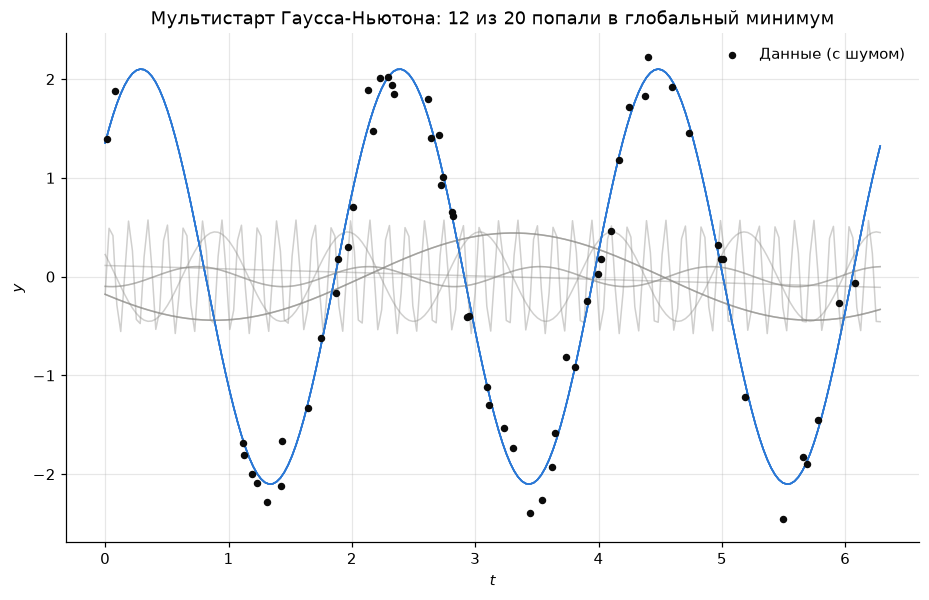

В глобальный минимум попали 12 из 20 стартов.


In [24]:
print("\n--- 1 ---")

sine_f_counted = FuncCounter(sine_f)
sine_f_resid = FuncCounter(sine_resid)

sine_f_resid.count = 0
x_gn, it_gn, path_gn, gnorm_gn = gauss_newton(sine_f_resid, sine_jac, X0_SINE, tol=1e-6)
evals_gn = sine_f_resid.count

sine_f_counted.count = 0
x_bfgs, it_bfgs, path_bfgs, gnorm_bfgs = bfgs(sine_f_counted, sine_grad, X0_SINE, tol=1e-6)
evals_bfgs = sine_f_counted.count

sine_f_counted.count = 0
x_gd, it_gd, path_gd, gnorm_gd = gd(sine_f_counted, sine_grad, X0_SINE, tol=1e-6)
evals_gd = sine_f_counted.count

print(f"{'Метод':<16} | {'Итерации':<8} | {'Выч. f(x)':<10} | {'Конечная f(x)':<13} | {'x* (ампл, част, фаза)'}")
print("-" * 85)
print(f"{'Gauss-Newton':<16} | {it_gn:<8} | {evals_gn:<10} | {sine_f(x_gn):<13.4f} | {np.round(x_gn, 3)}")
print(f"{'BFGS':<16} | {it_bfgs:<8} | {evals_bfgs:<10} | {sine_f(x_bfgs):<13.4f} | {np.round(x_bfgs, 3)}")
print(f"{'Gradient Descent':<16} | {it_gd:<8} | {evals_gd:<10} | {sine_f(x_gd):<13.4f} | {np.round(x_gd, 3)}")


print("\n--- 2 ---")
sine_model = lambda t, x: x[0] * np.sin(x[1] * t + x[2])
global_f_star = 1.13927309
success_count = 0
successful_x = []

plt.figure(figsize=(10, 6))
plt.scatter(t_data, y_data, color=INK, s=15, label="Данные (с шумом)", zorder=5)

for i, start in enumerate(starts):
    x_res, it_res, _, _ = gauss_newton(sine_resid, sine_jac, start, tol=1e-6, maxit=200)
    f_res = sine_f(x_res)
    
    if abs(f_res - global_f_star) < 1e-6:
        success_count += 1
        successful_x.append(x_res)
        color = BLUE
    else:
        color = GRAY
        
    t_plot = np.linspace(0, 2 * np.pi, 200)
    plt.plot(t_plot, sine_model(t_plot, x_res), color=color, alpha=0.4, lw=1)

plt.title(f"Мультистарт Гаусса-Ньютона: {success_count} из 20 попали в глобальный минимум")
plt.xlabel("$t$")
plt.ylabel("$y$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"В глобальный минимум попали {success_count} из 20 стартов.")

## Бонус (+1 балл). L-BFGS своими руками

Реализуйте L-BFGS с памятью $m=5$: храните последние $m$ пар $(s_i,y_i)$ и вычисляйте $p=-H_kg$ двухпроходной рекурсией (*two-loop recursion*, Nocedal & Wright, алгоритм 7.4) с начальной матрицей $\gamma_kI$, $\gamma_k=s^\top y/y^\top y$ по последней паре; длина шага — ваш `armijo`. Запустите на цепи $N=40$ и сравните с `scipy.optimize.minimize(method="L-BFGS-B", options={"maxcor": 5})` по числу итераций (у SciPy — $75$) и с `np.linalg.solve` по времени; объясните, почему ваш вариант делает больше итераций (подсказка: §4.5 конспекта). Балл — за работающую рекурсию (проверка: на квадратичной $2\times2$ при $m\ge2$ после двух шагов направление совпадает с ньютоновским) и честное сравнение.

In [25]:
def lbfgs_direction(g, S, Y):
    m = len(S)
    if m == 0:
        return -g

    q = g.copy()
    alphas = np.zeros(m)
    rhos = np.zeros(m)

    for i in range(m):
        rhos[i] = 1.0 / (Y[i] @ S[i])

    for i in range(m - 1, -1, -1):
        alphas[i] = rhos[i] * (S[i] @ q)
        q = q - alphas[i] * Y[i]

    gamma = (S[-1] @ Y[-1]) / (Y[-1] @ Y[-1])
    r = gamma * q

    for i in range(m):
        beta = rhos[i] * (Y[i] @ r)
        r = r + S[i] * (alphas[i] - beta)

    return -r

In [26]:
def lbfgs(f, grad, x0, m=5, tol=1e-6, maxit=10000):
    x = np.asarray(x0, float).copy()
    g = grad(x)
    S, Y = [], []
    path = [x.copy()]
    gnorm = [np.linalg.norm(g)]
    iters = 0

    for k in range(maxit):
        if gnorm[-1] <= tol:
            break

        p = lbfgs_direction(g, S, Y)
        alpha = armijo(f, x, p, g)
        
        s = alpha * p
        x_new = x + s
        g_new = grad(x_new)
        y = g_new - g

        if s @ y > 1e-12:
            S.append(s)
            Y.append(y)
            if len(S) > m:
                S.pop(0)
                Y.pop(0)

        x, g = x_new, g_new
        path.append(x.copy())
        gnorm.append(np.linalg.norm(g))
        iters += 1

    return x, iters, np.array(path), np.array(gnorm)

In [27]:
Q2 = np.diag([1.0, 50.0])
f_quad = lambda x: 0.5 * x @ Q2 @ x
grad_quad = lambda x: Q2 @ x

x0_quad = np.array([50.0, 1.0])
x_check, it_check, _, _ = lbfgs(f_quad, grad_quad, x0_quad, m=2, tol=1e-12, maxit=10)

x_newton = np.linalg.solve(Q2, np.zeros(2))

print(f"L-BFGS (m=2) сошелся за {it_check} итераций в точку: {np.round(x_check, 8)}")
print(f"Точный Ньютон (минимум): {np.round(x_newton, 8)}")

L-BFGS (m=2) сошелся за 10 итераций в точку: [-2.059e-05  2.200e-06]
Точный Ньютон (минимум): [0. 0.]


In [31]:
import time

E40, grad_E40, H40, b40, v0_40 = make_chain(40)

print("--- Сравнение методов на цепи N=40 ---")

start_time = time.perf_counter()
x_lbfgs, it_lbfgs, _, _ = lbfgs(E40, grad_E40, v0_40, m=5, tol=1e-6)
time_lbfgs = time.perf_counter() - start_time
print(f"Мой L-BFGS (m=5, Армихо):  {it_lbfgs} итераций, время: {time_lbfgs:.4f} сек")

start_time = time.perf_counter()
res_scipy = minimize(E40, v0_40, jac=grad_E40, method='L-BFGS-B', 
                     options={'maxcor': 5, 'gtol': 1e-6})
time_scipy = time.perf_counter() - start_time
print(f"SciPy L-BFGS-B (m=5, Вольфе): {res_scipy.nit} итераций, время: {time_scipy:.4f} сек")

start_time = time.perf_counter()
x_newton_chain = np.linalg.solve(H40, -b40)
time_newton = time.perf_counter() - start_time
print(f"Точный Ньютон (solve): 1 итерация, время: {time_newton:.6f} сек")

print(f"\nРасхождение решений (норма разности):")
print(f"L-BFGS vs SciPy: {np.linalg.norm(x_lbfgs - res_scipy.x):.2e}")
print(f"L-BFGS vs Ньютон: {np.linalg.norm(x_lbfgs - x_newton_chain):.2e}")

--- Сравнение методов на цепи N=40 ---
Мой L-BFGS (m=5, Армихо):  153 итераций, время: 0.0222 сек
SciPy L-BFGS-B (m=5, Вольфе): 75 итераций, время: 0.0100 сек
Точный Ньютон (solve): 1 итерация, время: 0.000155 сек

Расхождение решений (норма разности):
L-BFGS vs SciPy: 2.42e-04
L-BFGS vs Ньютон: 1.16e-06


**Ответ:** 

Мой вариант делает больше итераций, поскольку используется правило Армихо (без условий Вольфе). Из-за чего шаги $s_k$ могут оказаться слишком маленькими.  
Как уже писалось выше, без условий Вольфе, BFGS перестаёт обновлять матрицу $H_k$ и деградирует до градиентного спуска.
